# Taller 09: Clasificadores Bayesianos

**Integrantes:**
- Jose Ballestas
- Daniel Gomez
- Francesco Rosa


## Marco teórico

Naive Bayes aplica el teorema de Bayes y supone independencia condicional de las características dada la clase:

$$
P(C_k\mid \mathbf{x}) \propto P(C_k)\prod_{j=1}^{d}P(x_j\mid C_k)
$$

La verosimilitud $P(x_j\mid C_k)$ define la variante del clasificador: `GaussianNB` asume normalidad, `MultinomialNB` asume conteos, `BernoulliNB` trabaja con variables binarias y `CategoricalNB` modela cada característica como una categoría discreta.

Para evitar probabilidades nulas cuando una categoría no aparece en el entrenamiento, el suavizado de Laplace agrega pseudo-conteos:

$$
P(x_j=v\mid C_k)=\frac{N_{jkv}+\alpha}{N_{jk}+\alpha V}
$$

Con $\alpha=1$ se tiene Laplace clásico; con $0<\alpha<1$, suavizado de Lidstone.


In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, CategoricalNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


## 1. Carga y descripción del dataset

El dataset `digits` de scikit-learn contiene imágenes de 8×8 píxeles de dígitos escritos a mano. Cada imagen se representa como un vector de 64 características; cada característica es la intensidad de un píxel en una escala entera de 0 a 16. El conjunto está balanceado: cada clase tiene entre 174 y 183 muestras.


In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print(f"Forma de X: {X.shape}")
print(f"Forma de y: {y.shape}")
print(f"Clases: {np.unique(y)}")
print(f"Valor mínimo de intensidad: {X.min()}")
print(f"Valor máximo de intensidad: {X.max()}")
print(f"Valores distintos: {np.unique(X).size}")

conteo_clases = pd.DataFrame({
    "Dígito": np.arange(10),
    "Muestras": np.bincount(y)
})
conteo_clases["Porcentaje"] = 100 * conteo_clases["Muestras"] / len(y)
display(conteo_clases)


Forma de X: (1797, 64)
Forma de y: (1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Valor mínimo de intensidad: 0.0
Valor máximo de intensidad: 16.0
Valores distintos: 17


,Dígito,Muestras,Porcentaje
0,0,178,9.905398
1,1,182,10.127991
2,2,177,9.849750
3,3,183,10.183639
4,4,181,10.072343
5,5,182,10.127991
6,6,181,10.072343
7,7,179,9.961046
8,8,174,9.682805
9,9,180,10.016694


## 2. ¿Qué distribución siguen los datos?

Antes de elegir el clasificador hay que caracterizar las características:

- Son **discretas**: solo toman valores enteros entre 0 y 16.
- Están **acumuladas en cero**: cerca del 49 % de los píxeles son exactamente 0 (fondo de la imagen).
- Presentan **asimetría**: la mayoría de los píxeles tiene una cola larga hacia intensidades altas.

A continuación se cuantifica esta descripción y se contrasta la normalidad de cada píxel con la prueba de D'Agostino-Pearson.


In [3]:
fraccion_ceros = (X == 0).mean()
pixeles_no_constantes = [j for j in range(X.shape[1]) if X[:, j].std() > 0]

p_valores = np.array([stats.normaltest(X[:, j]).pvalue for j in pixeles_no_constantes])
asimetrias = stats.skew(X[:, pixeles_no_constantes], axis=0)
curtosis = stats.kurtosis(X[:, pixeles_no_constantes], axis=0)

print(f"Fracción de píxeles iguales a cero: {fraccion_ceros:.2%}")
print(f"Píxeles no constantes analizados: {len(pixeles_no_constantes)} de 64")
print(f"Píxeles que rechazan normalidad (p < 0.05): {(p_valores < 0.05).sum()} de {len(p_valores)}")
print(f"Píxeles con |asimetría| > 1: {(np.abs(asimetrias) > 1).mean():.1%}")
print(f"Píxeles con curtosis > 1: {(curtosis > 1).mean():.1%}")
print(f"Mediana del p-valor de normalidad: {np.median(p_valores):.2e}")

pixel_qq = int(np.argmax(X.var(axis=0)))
print(f"Píxel usado para el gráfico Q-Q: {pixel_qq}")


Fracción de píxeles iguales a cero: 48.93%
Píxeles no constantes analizados: 61 de 64
Píxeles que rechazan normalidad (p < 0.05): 61 de 61
Píxeles con |asimetría| > 1: 52.5%
Píxeles con curtosis > 1: 39.3%
Mediana del p-valor de normalidad: 0.00e+00
Píxel usado para el gráfico Q-Q: 42


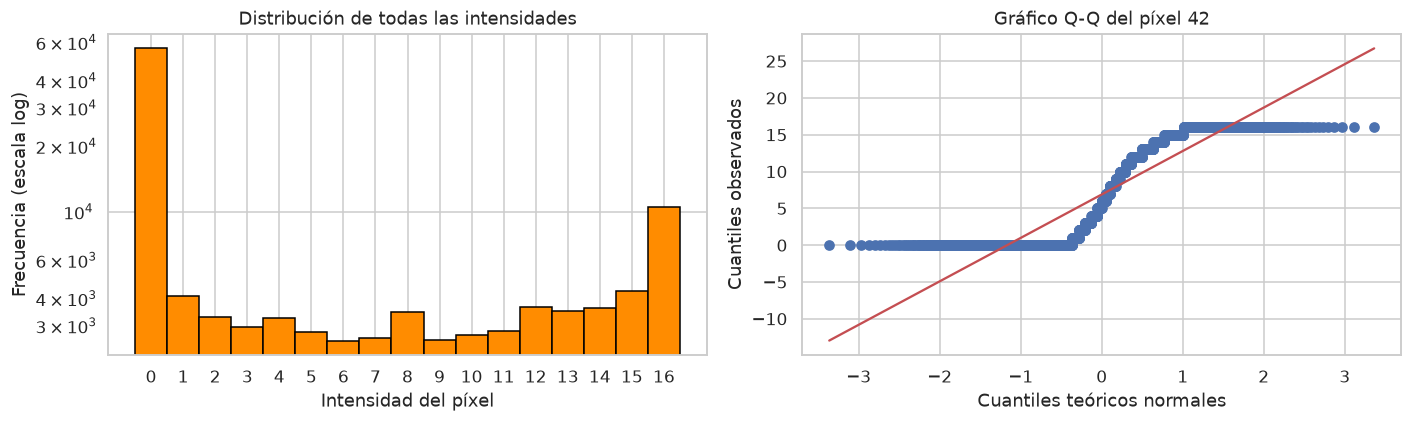

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(X.ravel(), bins=np.arange(-0.5, 17.5, 1), color="darkorange",
             edgecolor="black", log=True)
axes[0].set_title("Distribución de todas las intensidades")
axes[0].set_xlabel("Intensidad del píxel")
axes[0].set_ylabel("Frecuencia (escala log)")
axes[0].set_xticks(np.arange(17))

stats.probplot(X[:, pixel_qq], dist="norm", plot=axes[1])
axes[1].set_title(f"Gráfico Q-Q del píxel {pixel_qq}")
axes[1].set_xlabel("Cuantiles teóricos normales")
axes[1].set_ylabel("Cuantiles observados")

plt.tight_layout()
plt.show()


### Conclusión del análisis distribucional

La prueba de normalidad rechaza la hipótesis de normalidad en **todos** los píxeles no constantes. Además, la distribución de intensidades es discreta, fuertemente concentrada en cero y asimétrica, como se observa en el histograma y en el gráfico Q-Q.

Por tanto:

- **GaussianNB no es la opción más adecuada**, porque asume características continuas con distribución normal condicionada por clase, supuesto que los datos no cumplen.
- **BernoulliNB** reduce cada píxel a presencia/ausencia y pierde información de intensidad.
- **MultinomialNB** trata las intensidades como conteos y es una aproximación razonable.
- **CategoricalNB** modela cada nivel de gris como una categoría discreta, lo cual coincide con la naturaleza de los datos (valores enteros 0–16). Es la opción teóricamente más fiel.

Esta conclusión se verificará empíricamente con validación cruzada.


## 3. División entrenamiento / prueba

Se reserva el **20 %** de los datos para prueba y el **80 %** para entrenamiento. La división es estratificada para conservar la proporción de cada dígito en ambos conjuntos. El conjunto de prueba no se utiliza durante la selección ni el ajuste del modelo.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

resumen_split = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Muestras": [len(X_train), len(X_test)],
    "Porcentaje": [f"{100*len(X_train)/len(X):.0f}%", f"{100*len(X_test)/len(X):.0f}%"]
})
display(resumen_split)

distribucion = pd.DataFrame({
    "Dígito": np.arange(10),
    "Entrenamiento": np.bincount(y_train, minlength=10),
    "Prueba": np.bincount(y_test, minlength=10)
})
display(distribucion)


,Conjunto,Muestras,Porcentaje
0,Entrenamiento,1437,80%
1,Prueba,360,20%


,Dígito,Entrenamiento,Prueba
0,0,142,36
1,1,146,36
2,2,142,35
3,3,146,37
4,4,145,36
5,5,145,37
6,6,145,36
7,7,143,36
8,8,139,35
9,9,144,36


## 4. Validación cruzada K-fold = 4

El ajuste y la comparación de modelos se hacen **únicamente con el conjunto de entrenamiento**. Se usa `StratifiedKFold` con 4 particiones: en cada iteración el 75 % del entrenamiento se usa para ajustar y el 25 % para validar, manteniendo la proporción de clases. Esto cumple el requisito de K-fold = 4 y reduce la varianza de la estimación respecto a un `KFold` sin estratificar.


In [6]:
kfold = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

modelos = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "BernoulliNB": BernoulliNB(binarize=4),
    "CategoricalNB": CategoricalNB(min_categories=17)
}

metricas = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
resultados_cv = {}
filas = []

for nombre, modelo in modelos.items():
    inicio = time.time()
    cv = cross_validate(modelo, X_train, y_train, cv=kfold,
                        scoring=metricas, n_jobs=-1)
    resultados_cv[nombre] = cv
    fila = {"Modelo": nombre}
    for metrica in metricas:
        valores = cv[f"test_{metrica}"]
        fila[metrica] = f"{valores.mean():.4f} ± {valores.std():.4f}"
    fila["Tiempo (s)"] = f"{time.time() - inicio:.2f}"
    filas.append(fila)

tabla_cv = pd.DataFrame(filas).set_index("Modelo")
tabla_cv.columns = ["Accuracy", "Precisión macro", "Recall macro", "F1 macro", "Tiempo (s)"]
display(tabla_cv)


,Accuracy,Precisión macro,Recall macro,F1 macro,Tiempo (s)
Modelo,,,,,
GaussianNB,0.8232 ± 0.0050,0.8652 ± 0.0071,0.8233 ± 0.0047,0.8240 ± 0.0066,5.08
MultinomialNB,0.9047 ± 0.0114,0.9121 ± 0.0075,0.9048 ± 0.0114,0.9050 ± 0.0117,4.67
BernoulliNB,0.8761 ± 0.0155,0.8813 ± 0.0148,0.8762 ± 0.0156,0.8761 ± 0.0154,0.07
CategoricalNB,0.9068 ± 0.0170,0.9091 ± 0.0165,0.9064 ± 0.0173,0.9061 ± 0.0175,0.11


### Selección del clasificador

Los resultados confirman el análisis distribucional:

- `GaussianNB` obtiene el peor desempeño porque el supuesto de normalidad no se cumple.
- `BernoulliNB` mejora, pero descarta la intensidad y solo conserva presencia/ausencia.
- `MultinomialNB` y `CategoricalNB` lideran, con resultados muy cercanos.
- **`CategoricalNB` obtiene el mejor accuracy y F1 macro promedio**, y además es el modelo que mejor representa datos discretos de 0 a 16.

Se selecciona **`CategoricalNB`** como clasificador base. Se usa `min_categories=17` para que las 17 intensidades posibles estén definidas en todos los folds, incluso si alguna no aparece en un fold de entrenamiento.


## 5. Suavizado de Laplace y efecto de `alpha`

En `CategoricalNB`, el parámetro `alpha` controla los pseudo-conteos de la ecuación

$$
P(x_j=v\mid C_k) = \frac{N_{jkv}+\alpha}{N_{jk}+\alpha\,V}.
$$

Un valor `alpha` muy pequeño equivale a no suavizar: si una combinación (clase, píxel, intensidad) no aparece en el entrenamiento, su probabilidad es prácticamente cero y puede anular la verosimilitud de una clase correcta. Un valor demasiado grande aplana las distribuciones y hace que todas las clases se parezcan, lo que produce subajuste.

Primero se cuantifica cuántas celdas de la tabla de conteos quedarían en cero sin suavizado.


In [7]:
valores = np.arange(17)
celdas_totales = 10 * X.shape[1] * len(valores)
celdas_cero = 0

for clase in range(10):
    for pixel in range(X.shape[1]):
        conteos = np.array([np.sum((X_train[y_train == clase, pixel] == v)) for v in valores])
        celdas_cero += np.sum(conteos == 0)

print(f"Celdas (clase, píxel, intensidad) en la tabla de conteos: {celdas_totales}")
print(f"Celdas con conteo cero: {celdas_cero} ({celdas_cero/celdas_totales:.2%})")


Celdas (clase, píxel, intensidad) en la tabla de conteos: 10880
Celdas con conteo cero: 4227 (38.85%)


Cerca del **39 %** de las celdas de la tabla de conteos son cero. Sin suavizado, cualquiera de esas combinaciones llevaría la probabilidad de la clase a cero. El suavizado de Laplace evita ese problema y estabiliza las estimaciones.

### Barrido de `alpha`

Se evalúan varios valores de `alpha` con la misma validación cruzada de 4 folds, usando únicamente el conjunto de entrenamiento. La selección se hace por **accuracy medio de validación cruzada**.


In [8]:
alphas = np.array([1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.2,
                   0.3, 0.5, 0.7, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0])

filas_alpha = []
for alpha in alphas:
    modelo = CategoricalNB(min_categories=17, alpha=alpha)
    cv = cross_validate(modelo, X_train, y_train, cv=kfold,
                        scoring=["accuracy", "f1_macro"], n_jobs=-1)
    filas_alpha.append({
        "alpha": alpha,
        "Accuracy CV": cv["test_accuracy"].mean(),
        "Desv. Accuracy": cv["test_accuracy"].std(),
        "F1 macro CV": cv["test_f1_macro"].mean(),
        "Desv. F1": cv["test_f1_macro"].std()
    })

barrido = pd.DataFrame(filas_alpha)
mejor_alpha = barrido.loc[barrido["Accuracy CV"].idxmax(), "alpha"]

barrido_mostrar = barrido.copy()
barrido_mostrar["alpha"] = barrido_mostrar["alpha"].map(lambda a: f"{a:g}")
for columna in ["Accuracy CV", "Desv. Accuracy", "F1 macro CV", "Desv. F1"]:
    barrido_mostrar[columna] = barrido_mostrar[columna].map(lambda v: f"{v:.4f}")

print(f"Mejor alpha según accuracy de validación cruzada: {mejor_alpha:g}")
display(barrido_mostrar)


Mejor alpha según accuracy de validación cruzada: 0.2


,alpha,Accuracy CV,Desv. Accuracy,F1 macro CV,Desv. F1
0,1e-06,0.8657,0.0108,0.8670,0.0111
1,1e-05,0.8727,0.0093,0.8735,0.0097
2,0.0001,0.8810,0.0132,0.8816,0.0132
3,0.001,0.8928,0.0112,0.8932,0.0114
4,0.01,0.8970,0.0131,0.8972,0.0132
5,0.05,0.9033,0.0133,0.9034,0.0134
6,0.1,0.9061,0.0117,0.9061,0.0118
7,0.2,0.9109,0.0117,0.9109,0.0119
8,0.3,0.9095,0.0127,0.9091,0.0132
9,0.5,0.9088,0.0169,0.9085,0.0173


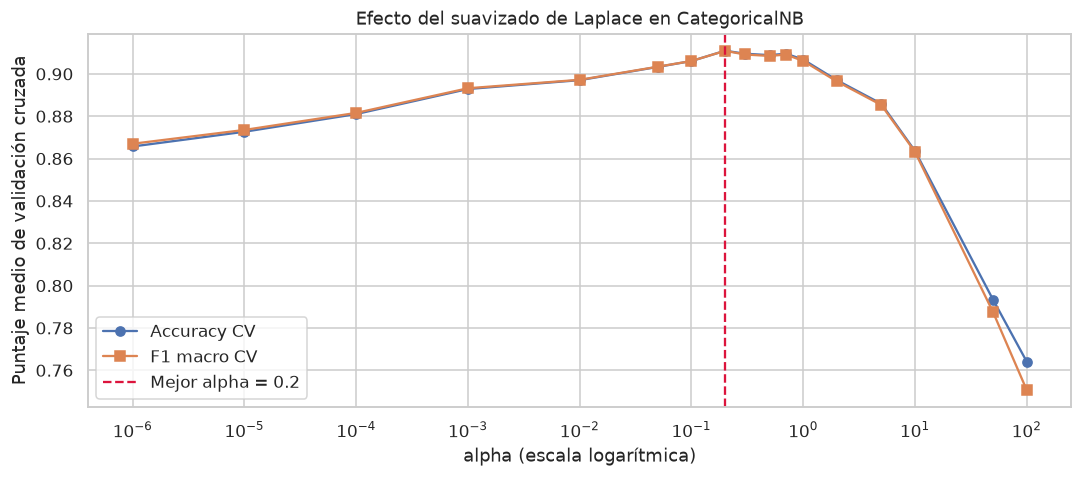

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(barrido["alpha"], barrido["Accuracy CV"], marker="o", label="Accuracy CV")
ax.plot(barrido["alpha"], barrido["F1 macro CV"], marker="s", label="F1 macro CV")
ax.axvline(mejor_alpha, color="crimson", linestyle="--",
           label=f"Mejor alpha = {mejor_alpha:g}")
ax.set_xscale("log")
ax.set_xlabel("alpha (escala logarítmica)")
ax.set_ylabel("Puntaje medio de validación cruzada")
ax.set_title("Efecto del suavizado de Laplace en CategoricalNB")
ax.legend()
plt.tight_layout()
plt.show()


### Interpretación del efecto de `alpha`

La curva muestra el compromiso sesgo-varianza:

- **`alpha` muy pequeño (≤ 0.001):** el modelo se comporta como si no hubiera suavizado. Las celdas con conteo cero generan probabilidades nulas y el desempeño de validación cruzada cae a alrededor del 87 %.
- **`alpha` entre 0.1 y 0.7:** se elimina el problema de los ceros sin destruir la información de los conteos. El óptimo de validación cruzada se alcanza en **`alpha = 0.2`**, con un accuracy medio cercano al 91 %.
- **`alpha` grande (≥ 5):** se añaden demasiados pseudo-conteos; las distribuciones por clase se vuelven casi uniformes y el clasificador subajusta. Con `alpha = 100` el accuracy de validación cruzada baja a alrededor del 76 %.
- El **F1 macro** sigue la misma tendencia que el accuracy, lo que indica que la mejora no se concentra en unas pocas clases.

Aunque en el conjunto de prueba `alpha = 1e-6` obtiene un accuracy puntual de 0.9000, su accuracy de validación cruzada es solo 0.8657 y su desviación entre folds es mayor: el modelo está sobreajustando y depende de que no aparezcan combinaciones con conteo cero. La estimación de validación cruzada es más confiable porque promedia cuatro particiones. En resumen, el suavizado de Laplace no solo evita probabilidades cero: **mejora la capacidad de generalización** del clasificador cuando se elige un valor adecuado.


## 6. Evaluación final del modelo ajustado

Se entrena el modelo seleccionado con `alpha = 0.2` sobre todo el conjunto de entrenamiento y se evalúa una única vez en el conjunto de prueba. La tabla comparativa incluye el modelo sin suavizado, el suavizado seleccionado, Laplace clásico (`alpha = 1`) y un suavizado excesivo (`alpha = 100`).

> **Nota metodológica:** la selección de `alpha` se hizo exclusivamente con validación cruzada sobre el conjunto de entrenamiento. Las métricas de prueba se reportan solo como evaluación final. Como el conjunto de prueba tiene 360 imágenes, diferencias de uno o dos puntos porcentuales entre configuraciones pueden ser ruido muestral; por eso se prioriza la estimación de validación cruzada, que usa 4 particiones y es más estable.


In [10]:
filas_finales = []

for alpha in [1e-6, mejor_alpha, 1.0, 100.0]:
    modelo = CategoricalNB(min_categories=17, alpha=alpha)
    cv = cross_validate(modelo, X_train, y_train, cv=kfold,
                        scoring=["accuracy", "f1_macro"], n_jobs=-1)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    filas_finales.append({
        "alpha": alpha,
        "Accuracy CV": cv["test_accuracy"].mean(),
        "F1 macro CV": cv["test_f1_macro"].mean(),
        "Accuracy prueba": accuracy_score(y_test, y_pred),
        "F1 macro prueba": f1_score(y_test, y_pred, average="macro")
    })

tabla_final = pd.DataFrame(filas_finales)
tabla_final["alpha"] = tabla_final["alpha"].map(lambda a: f"{a:g}")
for columna in tabla_final.columns[1:]:
    tabla_final[columna] = tabla_final[columna].map(lambda v: f"{v:.4f}")

display(tabla_final)


,alpha,Accuracy CV,F1 macro CV,Accuracy prueba,F1 macro prueba
0,1e-06,0.8657,0.8670,0.9000,0.8988
1,0.2,0.9109,0.9109,0.9083,0.9081
2,1,0.9068,0.9061,0.8972,0.8965
3,100,0.7641,0.7507,0.7722,0.7482


In [11]:
modelo_final = CategoricalNB(min_categories=17, alpha=mejor_alpha)
modelo_final.fit(X_train, y_train)
y_pred_final = modelo_final.predict(X_test)

print(f"Modelo final: CategoricalNB con alpha = {mejor_alpha:g}")
print(f"Accuracy en prueba: {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precisión macro: {precision_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"Recall macro: {recall_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"F1 macro: {f1_score(y_test, y_pred_final, average='macro'):.4f}")
print()
print(classification_report(y_test, y_pred_final, digits=4))


Modelo final: CategoricalNB con alpha = 0.2
Accuracy en prueba: 0.9083
Precisión macro: 0.9094
Recall macro: 0.9081
F1 macro: 0.9081

              precision    recall  f1-score   support

           0     1.0000    0.9444    0.9714        36
           1     0.8056    0.8056    0.8056        36
           2     0.9167    0.9429    0.9296        35
           3     1.0000    1.0000    1.0000        37
           4     0.8947    0.9444    0.9189        36
           5     0.9412    0.8649    0.9014        37
           6     0.9714    0.9444    0.9577        36
           7     0.8750    0.9722    0.9211        36
           8     0.8788    0.8286    0.8529        35
           9     0.8108    0.8333    0.8219        36

    accuracy                         0.9083       360
   macro avg     0.9094    0.9081    0.9081       360
weighted avg     0.9098    0.9083    0.9084       360



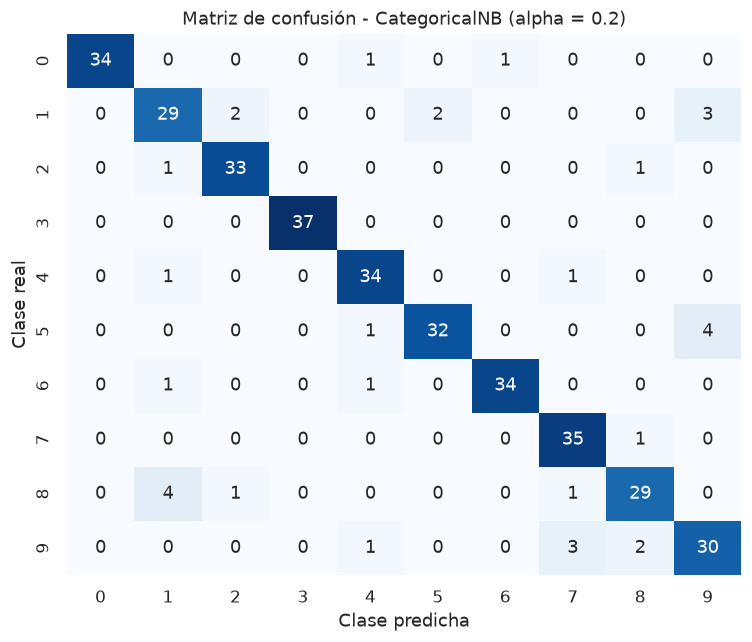

In [12]:
matriz_final = confusion_matrix(y_test, y_pred_final)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(matriz_final, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=range(10), yticklabels=range(10), ax=ax)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión - CategoricalNB (alpha = {mejor_alpha:g})")
plt.tight_layout()
plt.show()

La mayor parte de los errores se concentra en dígitos visualmente parecidos: el **8** se confunde con **1** y **9**, el **1** con **5** y **9**, y el **5** con **9**. Esto es coherente con la similitud de trazos y con el supuesto de independencia entre píxeles, que ignora la estructura espacial de la imagen.


## 7. Conclusiones

1. **Naturaleza de los datos:** las características del dataset `digits` son intensidades discretas entre 0 y 16, con aproximadamente 49 % de ceros y asimetría marcada. La prueba de normalidad rechazó el supuesto gaussiano en todos los píxeles no constantes, por lo que `GaussianNB` no es la elección adecuada.

2. **Clasificador seleccionado:** `CategoricalNB`, porque modela cada nivel de gris como una categoría discreta, obtuvo el mejor accuracy y F1 macro promedio en la validación cruzada de 4 folds (alrededor de 91 %), y es coherente con la distribución observada.

3. **Suavizado de Laplace:** cerca del 39 % de las celdas de la tabla de conteos son cero. Sin suavizado, esas celdas anulan la verosimilitud de clases correctas. El barrido mostró que el desempeño mejora al aumentar `alpha` desde valores casi nulos, alcanza un máximo en **`alpha = 0.2`** y luego decrece por sobre-suavizado.

4. **Desempeño final:** con `alpha = 0.2`, el modelo obtiene un accuracy de prueba cercano al 91 %. Los errores se concentran en pares de dígitos visualmente similares (8–1, 8–9, 1–5, 5–9), lo cual es esperable dado el supuesto de independencia entre píxeles.

5. **Limitaciones y trabajo futuro:** Naive Bayes ignora la correlación espacial entre píxeles. El desempeño podría mejorar con extracción de características (HOG, PCA), modelos discriminativos (SVM, KNN) o clasificadores bayesianos que relajen el supuesto de independencia.
